# Projeto Integrador Interdisciplinar II — Etapa 1
## Exploração inicial da base `history.csv` (Terra Signal)

**Objetivo deste notebook:** compreender a estrutura, a qualidade e o significado dos dados antes de qualquer tratamento, servindo de base para a Arquitetura Medalhão, o banco de dados/SQL e a análise exploratória das próximas etapas.

---
# 1. Importação das bibliotecas e configurações

Usamos apenas o necessário:

- **pandas**: leitura e manipulação da tabela;
- **matplotlib**: gráficos básicos (histogramas e barras);
- **seaborn**: boxplots comparando grupos (menos código que o matplotlib puro).

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

CAMINHO_BASE = "../bases/history.csv"

# Colunas com papel especial na análise
COLUNA_ID = "customerID"
COLUNA_ALVO = "Churn"
COLUNA_TEXTO = "CustomerFeedback"

# Valores informados no PDF (usados para conferência)
LINHAS_ESPERADAS_PDF = 5634
COLUNAS_ESPERADAS_PDF = 23

# Cores dos gráficos
COR_PRINCIPAL = "#2a78d6"
CORES_CHURN = {"No": "#2a78d6", "Yes": "#eb6834"}

# Configurações de exibição
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 60)
sns.set_theme(style="whitegrid")

---
# 2. Carregamento do dataset

**Objetivo:** carregar o CSV sem nenhuma transformação e conferir se o tamanho bate com o informado no pdf.

In [2]:
dados = pd.read_csv(CAMINHO_BASE)

quantidade_linhas, quantidade_colunas = dados.shape
print(f"Linhas: {quantidade_linhas}")
print(f"Colunas: {quantidade_colunas}")
print(f"Linhas conferem com o PDF? {quantidade_linhas == LINHAS_ESPERADAS_PDF}")
print(f"Colunas conferem com o PDF? {quantidade_colunas == COLUNAS_ESPERADAS_PDF}")

Linhas: 5634
Colunas: 23
Linhas conferem com o PDF? True
Colunas conferem com o PDF? True


In [3]:
dados.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,CustomerFeedback,MonthlyIncome
0,4578-PHJYZ,Male,0,Yes,Yes,52,Yes,No,DSL,No,Yes,Yes,Yes,Yes,No,One year,Yes,Electronic check,68.75,3482.85,No,I have been a customer with this internet provider for o...,6532
1,6289-CPNLD,Male,0,Yes,Yes,33,Yes,No,DSL,No,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,73.90,2405.05,Yes,I've been a customer with this company for over 2 and a ...,7634
2,2682-KEVRP,Female,1,No,No,22,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,20.05,417.00,No,I have been a customer with this company for 22 months n...,3628
3,5697-GOMBF,Female,1,Yes,Yes,28,No,No phone service,DSL,No,No,No,No,Yes,No,Month-to-month,Yes,Electronic check,35.90,973.65,No,I have been a customer with this internet provider for 2...,7851
4,9717-QEBGU,Male,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.30,144.00,No,I have been using the fiber optic internet service for t...,1691


In [4]:
dados.tail()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,CustomerFeedback,MonthlyIncome
5629,8909-BOLNL,Male,0,No,No,3,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,No,Mailed check,21.20,52.05,No,I have been a customer with this company for 3 months no...,8354
5630,2832-KJCRD,Female,0,No,No,38,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,103.65,3988.50,No,I have been a customer with this company for 38 months n...,9308
5631,7975-JMZNT,Male,0,Yes,No,66,Yes,Yes,DSL,Yes,Yes,Yes,Yes,Yes,Yes,Two year,No,Bank transfer (automatic),91.70,6075.90,No,I have been a customer with this DSL internet service pr...,2113
5632,4250-ZBWLV,Male,0,No,No,68,Yes,Yes,Fiber optic,No,Yes,Yes,Yes,Yes,Yes,One year,No,Electronic check,108.45,7176.55,Yes,I have been a customer with this company for over 5 year...,3904
5633,3915-ODIYG,Male,1,No,No,60,Yes,Yes,DSL,Yes,Yes,No,No,No,Yes,One year,Yes,Electronic check,71.75,4374.55,No,I have been a loyal customer of this internet service pr...,3016


**O que observar em `head()` e `tail()`:**

- Cada linha traz um `customerID` diferente, características pessoais, serviços contratados, valores financeiros, o `Churn` e um texto longo em `CustomerFeedback`.

In [5]:
dados.info()

<class 'pandas.DataFrame'>
RangeIndex: 5634 entries, 0 to 5633
Data columns (total 23 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        5634 non-null   str    
 1   gender            5634 non-null   str    
 2   SeniorCitizen     5634 non-null   int64  
 3   Partner           5634 non-null   str    
 4   Dependents        5634 non-null   str    
 5   tenure            5634 non-null   str    
 6   PhoneService      5634 non-null   str    
 7   MultipleLines     5634 non-null   str    
 8   InternetService   5634 non-null   str    
 9   OnlineSecurity    5634 non-null   str    
 10  OnlineBackup      5634 non-null   str    
 11  DeviceProtection  5634 non-null   str    
 12  TechSupport       5634 non-null   str    
 13  StreamingTV       5634 non-null   str    
 14  StreamingMovies   5634 non-null   str    
 15  Contract          5634 non-null   str    
 16  PaperlessBilling  5634 non-null   str    
 17  Paymen

**Interpretação de `info()`:**

- **Fato:** apenas `TotalCharges` tem valores nulos (5.356 não nulos de 5.634).
- **Fato:** `tenure` foi lida como **texto**, embora pareça numérica. Isso indica que existe pelo menos um valor não numérico na coluna (investigado na seção 6).
- **Fato:** `SeniorCitizen` é `int64`, mas as demais variáveis do tipo sim/não usam `Yes`/`No` em texto, codificações diferentes para o mesmo tipo de informação.

---
# 3. Visão geral da base

**Objetivo:** listar as colunas, separar numéricas e não numéricas (pelo tipo lido) e identificar candidatos a identificador e a variável temporal.

In [6]:
print("Colunas da base:")
print(dados.columns.tolist())

print("\nQuantidade de colunas por tipo lido pelo pandas:")
print(dados.dtypes.astype(str).value_counts())

Colunas da base:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn', 'CustomerFeedback', 'MonthlyIncome']

Quantidade de colunas por tipo lido pelo pandas:
str        19
int64       2
float64     2
Name: count, dtype: int64


In [7]:
colunas_numericas = dados.select_dtypes(include="number").columns.tolist()
colunas_nao_numericas = dados.select_dtypes(exclude="number").columns.tolist()

print(f"Numéricas pelo tipo lido ({len(colunas_numericas)}): {colunas_numericas}")
print(f"Não numéricas pelo tipo lido ({len(colunas_nao_numericas)}): {colunas_nao_numericas}")

Numéricas pelo tipo lido (4): ['SeniorCitizen', 'MonthlyCharges', 'TotalCharges', 'MonthlyIncome']
Não numéricas pelo tipo lido (19): ['customerID', 'gender', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'Churn', 'CustomerFeedback']


In [8]:
# Quantidade de valores distintos por coluna (cardinalidade)
dados.nunique().sort_values()

gender                 2
SeniorCitizen          2
Partner                2
Dependents             2
Churn                  2
PaperlessBilling       2
MultipleLines          3
OnlineBackup           3
TechSupport            3
StreamingTV            3
StreamingMovies        3
DeviceProtection       3
Contract               3
InternetService        3
OnlineSecurity         3
PhoneService           4
PaymentMethod          4
tenure                74
MonthlyCharges      1490
MonthlyIncome       4307
TotalCharges        5044
customerID          5634
CustomerFeedback    5634
dtype: int64

**O que observar:**

- A maioria das colunas tem **2 a 4 valores distintos** → são categóricas.
- `customerID` e `CustomerFeedback` têm 5.634 valores distintos (um por linha).
- `MonthlyCharges`, `TotalCharges` e `MonthlyIncome` têm alta cardinalidade → medidas contínuas.
- `tenure` tem 74 valores distintos: mais à frente veremos que são os números de 0 a 72 **mais** um valor em texto.
- `PhoneService` tem **4** valores, enquanto as outras colunas sim/não têm 2 → sinal de inconsistência (seção 6.4).

In [9]:
# Possíveis identificadores: colunas em que todos os valores são diferentes
candidatos_identificador = [
    coluna for coluna in dados.columns if dados[coluna].nunique() == len(dados)
]
print("Colunas com um valor diferente por linha:", candidatos_identificador)

# Possíveis variáveis temporais: colunas com tipo data ou com termos de tempo no nome
colunas_tipo_data = dados.select_dtypes(include="datetime").columns.tolist()
termos_temporais = ["date", "data", "time", "month", "year", "dt"]
colunas_nome_temporal = [
    coluna for coluna in dados.columns
    if any(termo in coluna.lower() for termo in termos_temporais)
]
print("Colunas com tipo data:", colunas_tipo_data)
print("Colunas com termo temporal no nome:", colunas_nome_temporal)

Colunas com um valor diferente por linha: ['customerID', 'CustomerFeedback']
Colunas com tipo data: []
Colunas com termo temporal no nome: ['MonthlyCharges', 'MonthlyIncome']


**Interpretação:**

- **Identificador:** `customerID` é o candidato natural. `CustomerFeedback` também é único por linha, mas é um texto livre, ser único não o torna um identificador.
- **Variáveis temporais:** não há nenhuma coluna de data. Os nomes `MonthlyCharges` e `MonthlyIncome` contêm "month", mas indicam **periodicidade de um valor** (mensal), não uma data. `tenure` representa uma **duração** (tempo de relacionamento), não um momento no tempo.

---
# 4. Estrutura e tipos de dados

**Objetivo:** montar um resumo por coluna (tipo, preenchimento, cardinalidade e exemplo) e diferenciar o **tipo Python** do **papel da variável no negócio**.

A função abaixo será reaproveitada no dicionário de dados (seção 9).

In [10]:
def resumir_colunas(df):
    # Retorna uma tabela com tipo, preenchimento, cardinalidade e um exemplo de cada coluna
    resumo = pd.DataFrame({
        "tipo_python": df.dtypes.astype(str),
        "nao_nulos": df.notna().sum(),
        "nulos": df.isna().sum(),
        "pct_nulos": (df.isna().mean() * 100).round(2),
        "pct_preenchido": (df.notna().mean() * 100).round(2),
        "valores_unicos": df.nunique(),
        "exemplo": df.iloc[0],
    })
    return resumo


resumo_colunas = resumir_colunas(dados)
resumo_colunas

,tipo_python,nao_nulos,nulos,pct_nulos,pct_preenchido,valores_unicos,exemplo
customerID,str,5634,0,0.00,100.00,5634,4578-PHJYZ
gender,str,5634,0,0.00,100.00,2,Male
SeniorCitizen,int64,5634,0,0.00,100.00,2,0
Partner,str,5634,0,0.00,100.00,2,Yes
Dependents,str,5634,0,0.00,100.00,2,Yes
tenure,str,5634,0,0.00,100.00,74,52
PhoneService,str,5634,0,0.00,100.00,4,Yes
MultipleLines,str,5634,0,0.00,100.00,3,No
InternetService,str,5634,0,0.00,100.00,3,DSL
OnlineSecurity,str,5634,0,0.00,100.00,3,No


In [11]:
def listar_valores_distintos(df, limite_categorias=10):
    # Mostra os valores distintos das colunas com poucas categorias
    for coluna in df.columns:
        if df[coluna].nunique() <= limite_categorias:
            valores = sorted(df[coluna].dropna().astype(str).unique())
            print(f"{coluna:<18} -> {valores}")


listar_valores_distintos(dados)

gender             -> ['Female', 'Male']
SeniorCitizen      -> ['0', '1']
Partner            -> ['No', 'Yes']
Dependents         -> ['No', 'Yes']
PhoneService       -> ['No', 'Yes', 'no', 'yes']
MultipleLines      -> ['No', 'No phone service', 'Yes']
InternetService    -> ['DSL', 'Fiber optic', 'No']
OnlineSecurity     -> ['No', 'No internet service', 'Yes']
OnlineBackup       -> ['No', 'No internet service', 'Yes']
DeviceProtection   -> ['No', 'No internet service', 'Yes']
TechSupport        -> ['No', 'No internet service', 'Yes']
StreamingTV        -> ['No', 'No internet service', 'Yes']
StreamingMovies    -> ['No', 'No internet service', 'Yes']
Contract           -> ['Month-to-month', 'One year', 'Two year']
PaperlessBilling   -> ['No', 'Yes']
PaymentMethod      -> ['Bank transfer (automatic)', 'Credit card (automatic)', 'Electronic check', 'Mailed check']
Churn              -> ['No', 'Yes']


**Classificação conceitual (papel da variável).** O tipo Python indica *como o dado foi armazenado*; o tipo conceitual indica *o que ele representa*. Exemplos de divergência encontrados:

| Coluna | Tipo Python | Papel real | Por quê |
|---|---|---|---|
| `SeniorCitizen` | int64 | booleana (0/1) | só possui os valores 0 e 1, não é uma medida |
| `tenure` | texto | numérica discreta (duração) | os valores são 0 a 72, mas existe um texto (`unknown`) que forçou a leitura como texto |
| `Partner`, `Churn`, etc. | texto | booleana (Yes/No) | só possuem duas respostas |
| `MultipleLines`, `OnlineSecurity`, etc. | texto | categórica com 3 níveis | além de Yes/No, existe "No phone service" / "No internet service" |
| `customerID` | texto | identificador | único por linha, sem significado numérico |

In [12]:
tipo_conceitual = {
    "customerID": "identificador",
    "gender": "categórica nominal (2 níveis)",
    "SeniorCitizen": "booleana codificada 0/1",
    "Partner": "booleana (Yes/No)",
    "Dependents": "booleana (Yes/No)",
    "tenure": "numérica discreta (duração)",
    "PhoneService": "booleana (Yes/No)",
    "MultipleLines": "categórica nominal (3 níveis)",
    "InternetService": "categórica nominal (3 níveis)",
    "OnlineSecurity": "categórica nominal (3 níveis)",
    "OnlineBackup": "categórica nominal (3 níveis)",
    "DeviceProtection": "categórica nominal (3 níveis)",
    "TechSupport": "categórica nominal (3 níveis)",
    "StreamingTV": "categórica nominal (3 níveis)",
    "StreamingMovies": "categórica nominal (3 níveis)",
    "Contract": "categórica ordinal (duração do contrato)",
    "PaperlessBilling": "booleana (Yes/No)",
    "PaymentMethod": "categórica nominal (4 níveis)",
    "MonthlyCharges": "numérica contínua (valor monetário)",
    "TotalCharges": "numérica contínua (valor monetário)",
    "Churn": "booleana (Yes/No) - variável de interesse",
    "CustomerFeedback": "texto livre",
    "MonthlyIncome": "numérica contínua (unidade não informada)",
}

resumo_colunas["tipo_conceitual"] = pd.Series(tipo_conceitual)
resumo_colunas[["tipo_python", "tipo_conceitual", "valores_unicos"]]

,tipo_python,tipo_conceitual,valores_unicos
customerID,str,identificador,5634
gender,str,categórica nominal (2 níveis),2
SeniorCitizen,int64,booleana codificada 0/1,2
Partner,str,booleana (Yes/No),2
Dependents,str,booleana (Yes/No),2
tenure,str,numérica discreta (duração),74
PhoneService,str,booleana (Yes/No),4
MultipleLines,str,categórica nominal (3 níveis),3
InternetService,str,categórica nominal (3 níveis),3
OnlineSecurity,str,categórica nominal (3 níveis),3


---
# 5. Qualidade dos dados

**Objetivo:** diagnosticar, sem corrigir, nulos, ausências "disfarçadas", duplicidades, inconsistências de grafia, inconsistências entre colunas e valores extremos.

## 5.1 Valores nulos

In [13]:
quantidade_nulos = dados.isna().sum()
tabela_nulos = pd.DataFrame({
    "nulos": quantidade_nulos,
    "pct_nulos": (quantidade_nulos / len(dados) * 100).round(2),
})
tabela_nulos[tabela_nulos["nulos"] > 0]

,nulos,pct_nulos
TotalCharges,278,4.93


**Resultado:** apenas `TotalCharges` tem nulos: **278 linhas (4,93%)**.

**Por que importa:** `TotalCharges` é uma das principais variáveis financeiras. Médias e somas calculadas sem tratar os nulos ignoram silenciosamente esses clientes.

## 5.2 Valores ausentes "disfarçados"

Procuramos textos vazios, espaços e marcadores comuns como `unknown`, `NA`, `?` e `-`.

In [14]:
MARCADORES_AUSENCIA = ["", "unknown", "na", "n/a", "nan", "null", "none", "?", "-"]


def contar_marcadores_ausencia(df, marcadores):
    # Conta, em cada coluna de texto, valores que parecem representar ausência de informação
    contagens = {}
    for coluna in df.select_dtypes(exclude="number").columns:
        valores = df[coluna].dropna().astype(str).str.strip().str.lower()
        quantidade = valores.isin(marcadores).sum()
        if quantidade > 0:
            contagens[coluna] = quantidade
    return pd.Series(contagens, name="ocorrencias", dtype="int64")


contar_marcadores_ausencia(dados, MARCADORES_AUSENCIA)

tenure    19
Name: ocorrencias, dtype: int64

In [15]:
# Quais valores de tenure não são números?
tenure_numerico = pd.to_numeric(dados["tenure"], errors="coerce")
valores_nao_numericos = dados.loc[tenure_numerico.isna(), "tenure"]

print("Valores não numéricos em tenure:")
print(valores_nao_numericos.value_counts())
print(f"Percentual da base: {len(valores_nao_numericos) / len(dados) * 100:.2f}%")

Valores não numéricos em tenure:
tenure
unknown    19
Name: count, dtype: int64
Percentual da base: 0.34%


> **Sobre `tenure_numerico`:** é uma **cópia** de `tenure` convertida para número, criada apenas para permitir cálculos neste notebook. `errors="coerce"` transforma em nulo o que não for número (o `unknown`). A coluna original em `dados` continua intacta.

In [16]:
# As linhas com tenure "unknown" têm os demais campos financeiros preenchidos?
linhas_tenure_desconhecido = dados[tenure_numerico.isna()]
linhas_tenure_desconhecido[[COLUNA_ID, "tenure", "MonthlyCharges", "TotalCharges", COLUNA_ALVO]]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
1059,7301-ABVAD,unknown,86.60,6350.50,No
1097,9651-GTSAQ,unknown,106.10,NaN,Yes
1791,0135-NMXAP,unknown,89.75,1052.40,Yes
1984,3892-NXAZG,unknown,114.05,8289.20,No
2361,3934-HXCFZ,unknown,99.25,2186.40,Yes
2372,1622-HSHSF,unknown,19.55,19.55,No
2641,6907-NZZIJ,unknown,99.15,3615.60,Yes
2896,6023-GSSXW,unknown,61.45,4131.20,No
2936,5688-KZTSN,unknown,20.00,288.05,Yes
2959,7694-VLBWQ,unknown,104.10,7040.85,Yes


In [17]:
# Existe sobreposição entre os dois problemas de ausência?
ausencia_tenure = tenure_numerico.isna()
ausencia_total_charges = dados["TotalCharges"].isna()

print("tenure 'unknown':", ausencia_tenure.sum())
print("TotalCharges nulo:", ausencia_total_charges.sum())
print("Ambos ao mesmo tempo:", (ausencia_tenure & ausencia_total_charges).sum())
print("Linhas com pelo menos um dos dois:", (ausencia_tenure | ausencia_total_charges).sum())

tenure 'unknown': 19
TotalCharges nulo: 278
Ambos ao mesmo tempo: 1
Linhas com pelo menos um dos dois: 296


**Resultado:**

- **Fato:** `tenure` tem **19 valores `unknown` (0,34%)**, é uma ausência que não aparece em `isna()`.
- **Fato:** não há strings vazias nem outros marcadores de ausência nas demais colunas de texto.
- **Fato:** só 1 linha tem os dois problemas; **296 linhas (5,25%)** têm ao menos um deles.
- **Inferência:** em 18 das 19 linhas com `tenure` desconhecido, `TotalCharges` e `MonthlyCharges` estão preenchidos, o que pode permitir uma estimativa futura (ver 6.5). Essa decisão fica para a Silver.

## 5.3 Duplicidades

In [18]:
linhas_duplicadas = dados.duplicated().sum()
ids_duplicados = dados[COLUNA_ID].duplicated().sum()

# Duplicidade "disfarçada": mesmo conteúdo com IDs diferentes.
# O feedback é removido da comparação porque é um texto único por linha.
colunas_sem_id_e_texto = dados.columns.drop([COLUNA_ID, COLUNA_TEXTO])
duplicadas_sem_id = dados.duplicated(subset=colunas_sem_id_e_texto).sum()

print(f"Linhas completamente duplicadas: {linhas_duplicadas}")
print(f"customerID repetidos: {ids_duplicados}")
print(f"Linhas iguais ignorando ID e feedback: {duplicadas_sem_id}")

Linhas completamente duplicadas: 0
customerID repetidos: 0
Linhas iguais ignorando ID e feedback: 0


**Resultado:** nenhuma duplicidade em nenhum dos três critérios.

**Interpretação:** se existissem linhas iguais com IDs diferentes, elas poderiam ser **legítimas** (dois clientes com o mesmo perfil), por isso esse critério é apenas um alerta, não uma regra de remoção. Como o resultado é zero, a questão não precisa ser decidida agora.

## 5.4 Inconsistências de grafia e formato

In [19]:
def encontrar_variacoes_de_grafia(serie):
    # Agrupa valores que ficam iguais depois de remover espaços e passar para minúsculas
    valores_distintos = pd.Series(serie.dropna().astype(str).unique())
    valor_padronizado = valores_distintos.str.strip().str.lower()
    grupos = valores_distintos.groupby(valor_padronizado).apply(list)
    return grupos[grupos.apply(len) > 1]


colunas_categoricas_texto = dados.select_dtypes(exclude="number").columns.drop(
    [COLUNA_ID, COLUNA_TEXTO, "tenure"]
)

for coluna in colunas_categoricas_texto:
    variacoes = encontrar_variacoes_de_grafia(dados[coluna])
    if not variacoes.empty:
        print(f"{coluna}: {variacoes.to_dict()}")

PhoneService: {'no': ['No', 'no'], 'yes': ['Yes', 'yes']}


In [20]:
dados["PhoneService"].value_counts()

PhoneService
Yes    5041
No      523
no       40
yes      30
Name: count, dtype: int64

In [21]:
# Espaços sobrando no início ou no fim dos textos
colunas_texto = dados.select_dtypes(exclude="number").columns
for coluna in colunas_texto:
    textos = dados[coluna].dropna().astype(str)
    quantidade_com_espacos = (textos != textos.str.strip()).sum()
    print(f"{coluna:<18} -> {quantidade_com_espacos} valores com espaços extras")

customerID         -> 0 valores com espaços extras
gender             -> 0 valores com espaços extras


Partner            -> 0 valores com espaços extras
Dependents         -> 0 valores com espaços extras
tenure             -> 0 valores com espaços extras
PhoneService       -> 0 valores com espaços extras
MultipleLines      -> 0 valores com espaços extras
InternetService    -> 0 valores com espaços extras
OnlineSecurity     -> 0 valores com espaços extras
OnlineBackup       -> 0 valores com espaços extras
DeviceProtection   -> 0 valores com espaços extras
TechSupport        -> 0 valores com espaços extras
StreamingTV        -> 0 valores com espaços extras
StreamingMovies    -> 0 valores com espaços extras
Contract           -> 0 valores com espaços extras
PaperlessBilling   -> 0 valores com espaços extras
PaymentMethod      -> 0 valores com espaços extras
Churn              -> 0 valores com espaços extras


CustomerFeedback   -> 0 valores com espaços extras


In [22]:
# O formato do customerID é sempre o mesmo? (4 dígitos, hífen, 5 letras maiúsculas)
PADRAO_ID = r"^\d{4}-[A-Z]{5}$"
segue_padrao = dados[COLUNA_ID].str.match(PADRAO_ID)
print(f"IDs no padrão 0000-AAAAA: {segue_padrao.sum()} de {len(dados)}")

IDs no padrão 0000-AAAAA: 5634 de 5634

**Resultado:**

- **Fato:** `PhoneService` tem **70 valores em minúsculas** (`no` = 40, `yes` = 30), 1,24% da base. Sem padronização, `Yes` e `yes` seriam contados como categorias diferentes.
- **Fato:** nenhuma outra coluna categórica tem variação de capitalização; não há espaços extras.
- **Fato:** 100% dos `customerID` seguem o mesmo formato.
- **Fato:** `SeniorCitizen` usa 0/1 enquanto as demais colunas booleanas usam Yes/No (inconsistência de **codificação** entre colunas, não um erro de valor).

## 5.5 Consistência entre colunas

Algumas colunas dependem logicamente de outras. Verificamos se as regras implícitas são respeitadas.

In [23]:
# Regra esperada: quem não tem telefone deve ter MultipleLines = "No phone service"
pd.crosstab(dados["PhoneService"], dados["MultipleLines"])

MultipleLines,No,No phone service,Yes
PhoneService,,,
No,0,523,0
Yes,2687,0,2354
no,0,40,0
yes,17,0,13


In [24]:
# Regra esperada: quem não tem internet deve ter "No internet service" nos serviços adicionais
SERVICOS_INTERNET = [
    "OnlineSecurity", "OnlineBackup", "DeviceProtection",
    "TechSupport", "StreamingTV", "StreamingMovies",
]

sem_internet = dados["InternetService"] == "No"
for servico in SERVICOS_INTERNET:
    marcado_sem_internet = dados[servico] == "No internet service"
    inconsistencias = (sem_internet != marcado_sem_internet).sum()
    print(f"{servico:<17} -> {inconsistencias} inconsistências")

OnlineSecurity    -> 0 inconsistências
OnlineBackup      -> 0 inconsistências
DeviceProtection  -> 0 inconsistências
TechSupport       -> 0 inconsistências
StreamingTV       -> 0 inconsistências
StreamingMovies   -> 0 inconsistências


In [25]:
# Clientes com tenure = 0 (possivelmente recém-chegados) e o TotalCharges deles
clientes_tenure_zero = dados[tenure_numerico == 0]
print(f"Clientes com tenure = 0: {len(clientes_tenure_zero)}")
print(f"Desses, com TotalCharges nulo: {clientes_tenure_zero['TotalCharges'].isna().sum()}")
print(f"TotalCharges nulo com tenure > 0: {(ausencia_total_charges & (tenure_numerico > 0)).sum()}")

Clientes com tenure = 0: 10
Desses, com TotalCharges nulo: 10
TotalCharges nulo com tenure > 0: 267


In [26]:
# TotalCharges deveria ser próximo de tenure x MonthlyCharges (se tenure estiver em meses)
total_estimado = tenure_numerico * dados["MonthlyCharges"]
razao_total_estimado = dados["TotalCharges"] / total_estimado

print("Razão TotalCharges / (tenure x MonthlyCharges):")
print(razao_total_estimado.describe().round(3))
fora_da_faixa = ((razao_total_estimado < 0.8) | (razao_total_estimado > 1.2)).sum()
print(f"\nRazões fora da faixa 0,8 a 1,2: {fora_da_faixa}")

Razão TotalCharges / (tenure x MonthlyCharges):
count    5338.000
mean        1.000
std         0.051
min         0.689
25%         0.980
50%         1.000
75%         1.020
max         1.495
dtype: float64

Razões fora da faixa 0,8 a 1,2: 47


**Resultado:**

- **Fato:** `PhoneService` × `MultipleLines` é consistente, os 563 clientes sem telefone (523 `No` + 40 `no`) estão todos como "No phone service".
- **Fato:** os 6 serviços adicionais são 100% consistentes com `InternetService` (1.233 clientes sem internet).
- **Fato:** os 10 clientes com `tenure = 0` têm `TotalCharges` nulo. Porém, 267 nulos ocorrem em clientes com `tenure > 0`.
- **Inferência:** para `tenure = 0`, o nulo pode significar "ainda não houve cobrança" (nulo **estrutural**). Para os demais 267, o nulo parece ser **falta de informação**, são situações diferentes que podem exigir tratamentos diferentes.
- **Fato:** a razão `TotalCharges / (tenure × MonthlyCharges)` tem mediana 1,0 e quartis entre 0,98 e 1,02.
- **Inferência (confiança alta):** `TotalCharges` é o valor acumulado cobrado ao longo do relacionamento, e `tenure` está na mesma unidade de tempo de `MonthlyCharges` (meses). As pequenas diferenças podem ser variações no valor mensal ao longo do tempo — **não é possível confirmar** com os dados disponíveis.

## 5.6 Valores extremos (outliers)

Usamos a regra do intervalo interquartil (IQR): é extremo o valor abaixo de Q1 − 1,5×IQR ou acima de Q3 + 1,5×IQR

In [27]:
# Cópia temporária só com as medidas numéricas (tenure convertido para número)
dados_numericos = pd.DataFrame({
    "tenure": tenure_numerico,
    "MonthlyCharges": dados["MonthlyCharges"],
    "TotalCharges": dados["TotalCharges"],
    "MonthlyIncome": dados["MonthlyIncome"],
})


def resumir_outliers_iqr(df):
    # Calcula os limites do IQR e quantos valores ficam fora deles em cada coluna
    linhas = []
    for coluna in df.columns:
        serie = df[coluna].dropna()
        q1 = serie.quantile(0.25)
        q3 = serie.quantile(0.75)
        iqr = q3 - q1
        limite_inferior = q1 - 1.5 * iqr
        limite_superior = q3 + 1.5 * iqr
        quantidade = ((serie < limite_inferior) | (serie > limite_superior)).sum()
        linhas.append({
            "coluna": coluna,
            "minimo": serie.min(),
            "maximo": serie.max(),
            "limite_inferior": round(limite_inferior, 2),
            "limite_superior": round(limite_superior, 2),
            "outliers": quantidade,
        })
    return pd.DataFrame(linhas).set_index("coluna")


resumir_outliers_iqr(dados_numericos)

,minimo,maximo,limite_inferior,limite_superior,outliers
coluna,,,,,
tenure,0.0,72.00,-60.00,124.00,0
MonthlyCharges,18.4,118.65,-46.79,171.76,0
TotalCharges,18.8,8684.80,-4562.38,8705.02,0
MonthlyIncome,100.0,9993.00,-4627.75,14896.25,0


In [28]:
# Checagens de plausibilidade (valores impossíveis ou suspeitos)
print("Valores negativos em alguma medida:", (dados_numericos < 0).sum().sum())
print("MonthlyIncome menor que MonthlyCharges:", (dados["MonthlyIncome"] < dados["MonthlyCharges"]).sum())
print("MonthlyIncome até 500:", (dados["MonthlyIncome"] <= 500).sum())

Valores negativos em alguma medida: 0
MonthlyIncome menor que MonthlyCharges: 1
MonthlyIncome até 500: 190


**Resultado:**

- **Fato:** nenhuma variável numérica tem outliers pela regra do IQR, e não há valores negativos.
- **Fato:** `tenure` vai de 0 a 72; `MonthlyCharges` de 18,40 a 118,65; `TotalCharges` de 18,80 a 8.684,80.
- **Ponto de atenção:** `MonthlyIncome` vai de 100 a 9.993. Em 1 caso a renda é menor que a mensalidade e 190 clientes têm valor até 500. Como **a unidade e a moeda de `MonthlyIncome` não são informadas**, não é possível dizer se esses valores são implausíveis.

## 5.7 Resumo dos problemas de qualidade

Tabela montada com as contagens calculadas acima (nenhum número digitado à mão).

In [29]:
total_linhas = len(dados)
qtd_phone_minusculo = dados["PhoneService"].isin(["yes", "no"]).sum()

problemas_qualidade = pd.DataFrame([
    {
        "problema": "Valores nulos",
        "coluna": "TotalCharges",
        "ocorrencias": ausencia_total_charges.sum(),
        "relevancia": "Afeta somas e médias financeiras",
        "tratamento_futuro_silver": "Separar nulos de tenure=0 (estruturais) dos demais; decidir entre manter nulo, estimar ou sinalizar",
    },
    {
        "problema": "Ausência disfarçada ('unknown')",
        "coluna": "tenure",
        "ocorrencias": ausencia_tenure.sum(),
        "relevancia": "Impede o tipo numérico e cálculos de tempo de relacionamento",
        "tratamento_futuro_silver": "Converter 'unknown' em nulo e tenure para inteiro; avaliar estimativa por TotalCharges/MonthlyCharges",
    },
    {
        "problema": "Capitalização inconsistente",
        "coluna": "PhoneService",
        "ocorrencias": qtd_phone_minusculo,
        "relevancia": "Cria categorias falsas (yes/Yes) e distorce frequências",
        "tratamento_futuro_silver": "Padronizar para Yes/No",
    },
    {
        "problema": "Codificação diferente para booleanos",
        "coluna": "SeniorCitizen",
        "ocorrencias": total_linhas,
        "relevancia": "Mistura 0/1 e Yes/No para o mesmo tipo de informação",
        "tratamento_futuro_silver": "Definir um padrão único para colunas booleanas",
    },
    {
        "problema": "Tipo lido incorretamente",
        "coluna": "tenure",
        "ocorrencias": total_linhas,
        "relevancia": "Coluna numérica armazenada como texto",
        "tratamento_futuro_silver": "Converter para inteiro após tratar 'unknown'",
    },
])

problemas_qualidade["pct_base"] = (problemas_qualidade["ocorrencias"] / total_linhas * 100).round(2)
problemas_qualidade

,problema,coluna,ocorrencias,relevancia,tratamento_futuro_silver,pct_base
0,Valores nulos,TotalCharges,278,Afeta somas e médias financeiras,Separar nulos de tenure=0 (estruturais) dos demais; deci...,4.93
1,Ausência disfarçada ('unknown'),tenure,19,Impede o tipo numérico e cálculos de tempo de relacionam...,Converter 'unknown' em nulo e tenure para inteiro; avali...,0.34
2,Capitalização inconsistente,PhoneService,70,Cria categorias falsas (yes/Yes) e distorce frequências,Padronizar para Yes/No,1.24
3,Codificação diferente para booleanos,SeniorCitizen,5634,Mistura 0/1 e Yes/No para o mesmo tipo de informação,Definir um padrão único para colunas booleanas,100.00
4,Tipo lido incorretamente,tenure,5634,Coluna numérica armazenada como texto,Converter para inteiro após tratar 'unknown',100.00


---
# 6. Análise das variáveis

## 6.1 Variáveis numéricas

Analisamos as quatro medidas numéricas. `SeniorCitizen` fica de fora porque, apesar de ser número, é uma variável booleana (analisada em 7.2).

In [30]:
estatisticas_numericas = dados_numericos.describe().T
estatisticas_numericas["mediana"] = dados_numericos.median()
estatisticas_numericas["assimetria"] = dados_numericos.skew()
estatisticas_numericas.round(2)

,count,mean,std,min,25%,50%,75%,max,mediana,assimetria
tenure,5615.0,32.31,24.48,0.0,9.00,29.00,55.00,72.00,29.00,0.24
MonthlyCharges,5634.0,64.61,30.15,18.4,35.16,70.30,89.80,118.65,70.30,-0.21
TotalCharges,5356.0,2271.88,2253.78,18.8,412.90,1390.72,3729.75,8684.80,1390.72,0.97
MonthlyIncome,5634.0,5104.88,2839.23,100.0,2693.75,5079.50,7574.75,9993.00,5079.50,-0.01


**Pergunta que os gráficos respondem:** como os valores se distribuem? Há concentração, assimetria ou valores isolados?

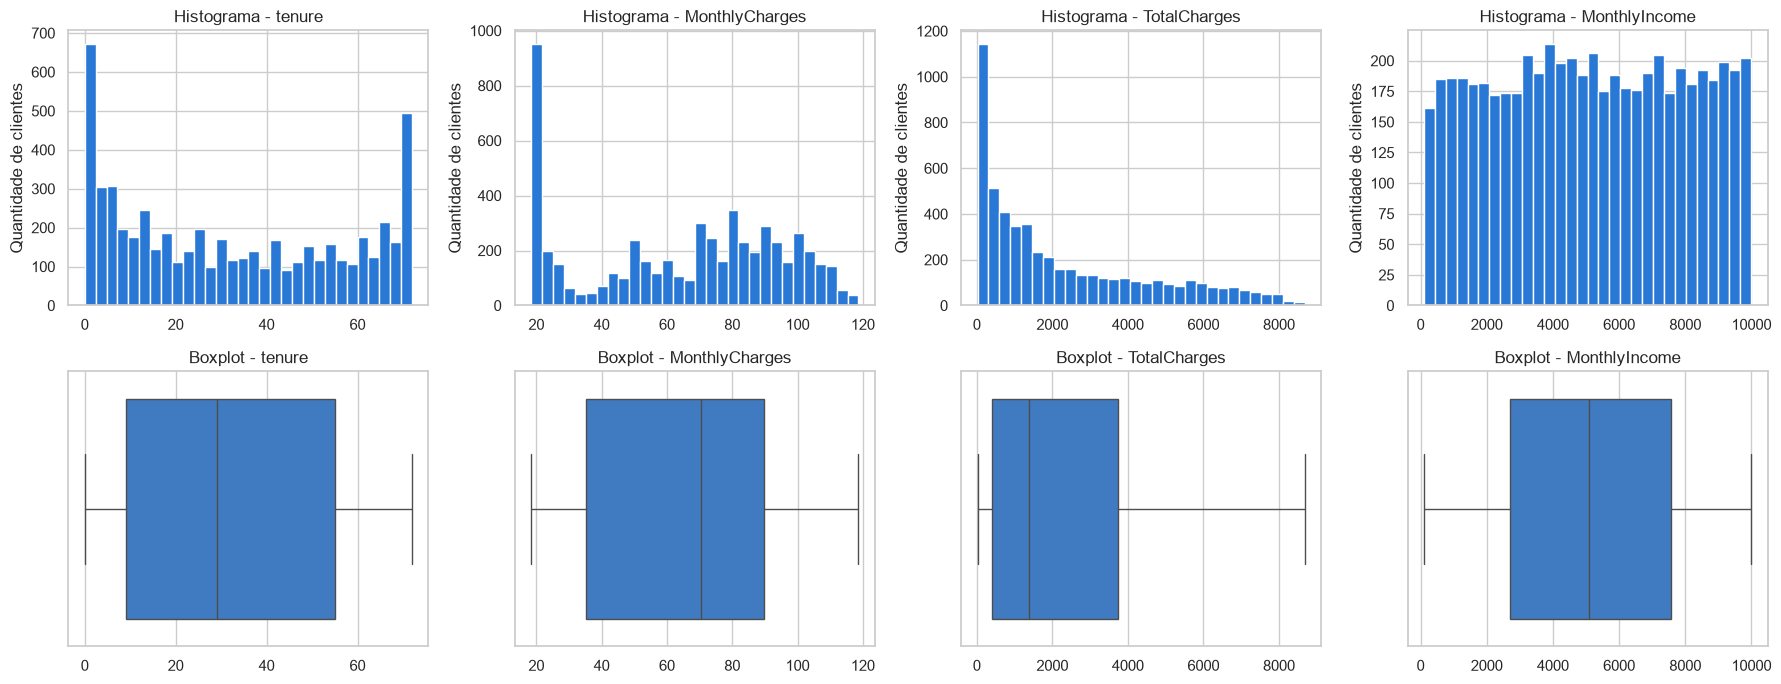

In [31]:
fig, eixos = plt.subplots(2, 4, figsize=(18, 7))

for posicao, coluna in enumerate(dados_numericos.columns):
    valores = dados_numericos[coluna].dropna()

    eixos[0, posicao].hist(valores, bins=30, color=COR_PRINCIPAL, edgecolor="white")
    eixos[0, posicao].set_title(f"Histograma - {coluna}")
    eixos[0, posicao].set_ylabel("Quantidade de clientes")

    sns.boxplot(x=valores, color=COR_PRINCIPAL, ax=eixos[1, posicao])
    eixos[1, posicao].set_title(f"Boxplot - {coluna}")
    eixos[1, posicao].set_xlabel("")

plt.tight_layout()
plt.show()

**Interpretação:**

| Variável | O que os números e gráficos mostram (fato) | Leitura (inferência) |
|---|---|---|
| `tenure` | Média 32,3 e mediana 29; picos nos extremos (perto de 0 e perto de 72) | Carteira com muitos clientes novos e muitos clientes antigos |
| `MonthlyCharges` | Média 64,6 < mediana 70,3; concentração perto de 20 e outra entre 70 e 100 | Provavelmente dois perfis: planos básicos e planos com mais serviços |
| `TotalCharges` | Média 2.271,9 bem acima da mediana 1.390,7; assimetria positiva (0,97) | Muitos clientes acumularam pouco; poucos acumularam muito, coerente com ser um valor acumulado |
| `MonthlyIncome` | Média 5.104,9 ≈ mediana 5.079,5; quartis igualmente espaçados; histograma "plano" | Distribuição **aproximadamente uniforme** entre 100 e 9.993, padrão incomum para renda real |

**Implicação:** para `TotalCharges` a **mediana** é a medida central mais adequada (distribuição assimétrica). A distribuição uniforme de `MonthlyIncome` é um alerta: **hipótese** de que seja uma variável gerada artificialmente, a ser considerada ao interpretar resultados que a envolvam.

## 7.2 Variáveis categóricas

In [32]:
def tabela_frequencia(serie):
    # Frequência absoluta e relativa (%) de cada categoria, incluindo nulos
    frequencia_absoluta = serie.value_counts(dropna=False)
    frequencia_relativa = (serie.value_counts(dropna=False, normalize=True) * 100).round(2)
    return pd.DataFrame({
        "freq_absoluta": frequencia_absoluta,
        "freq_relativa_pct": frequencia_relativa,
    })


colunas_categoricas = [
    "gender", "SeniorCitizen", "Partner", "Dependents",
    "PhoneService", "MultipleLines", "InternetService",
    "OnlineSecurity", "OnlineBackup", "DeviceProtection",
    "TechSupport", "StreamingTV", "StreamingMovies",
    "Contract", "PaperlessBilling", "PaymentMethod", "Churn",
]

for coluna in colunas_categoricas:
    print(f"\n=== {coluna} ===")
    print(tabela_frequencia(dados[coluna]))


=== gender ===
        freq_absoluta  freq_relativa_pct
gender                                  
Male             2835              50.32
Female           2799              49.68

=== SeniorCitizen ===
               freq_absoluta  freq_relativa_pct
SeniorCitizen                                  
0                       4706              83.53
1                        928              16.47

=== Partner ===
         freq_absoluta  freq_relativa_pct
Partner                                  
No                2907               51.6
Yes               2727               48.4

=== Dependents ===
            freq_absoluta  freq_relativa_pct
Dependents                                  
No                   3949              70.09
Yes                  1685              29.91

=== PhoneService ===
              freq_absoluta  freq_relativa_pct
PhoneService                                  
Yes                    5041              89.47
No                      523               9.28
no        

In [33]:
# Categorias raras: menos de 5% da base
LIMITE_CATEGORIA_RARA_PCT = 5

for coluna in colunas_categoricas:
    frequencias = tabela_frequencia(dados[coluna])
    raras = frequencias[frequencias["freq_relativa_pct"] < LIMITE_CATEGORIA_RARA_PCT]
    if not raras.empty:
        print(f"{coluna}: {raras['freq_relativa_pct'].to_dict()}")

PhoneService: {'no': 0.71, 'yes': 0.53}


**Pergunta que o gráfico responde:** como a carteira se distribui em cada característica? Quais categorias predominam?

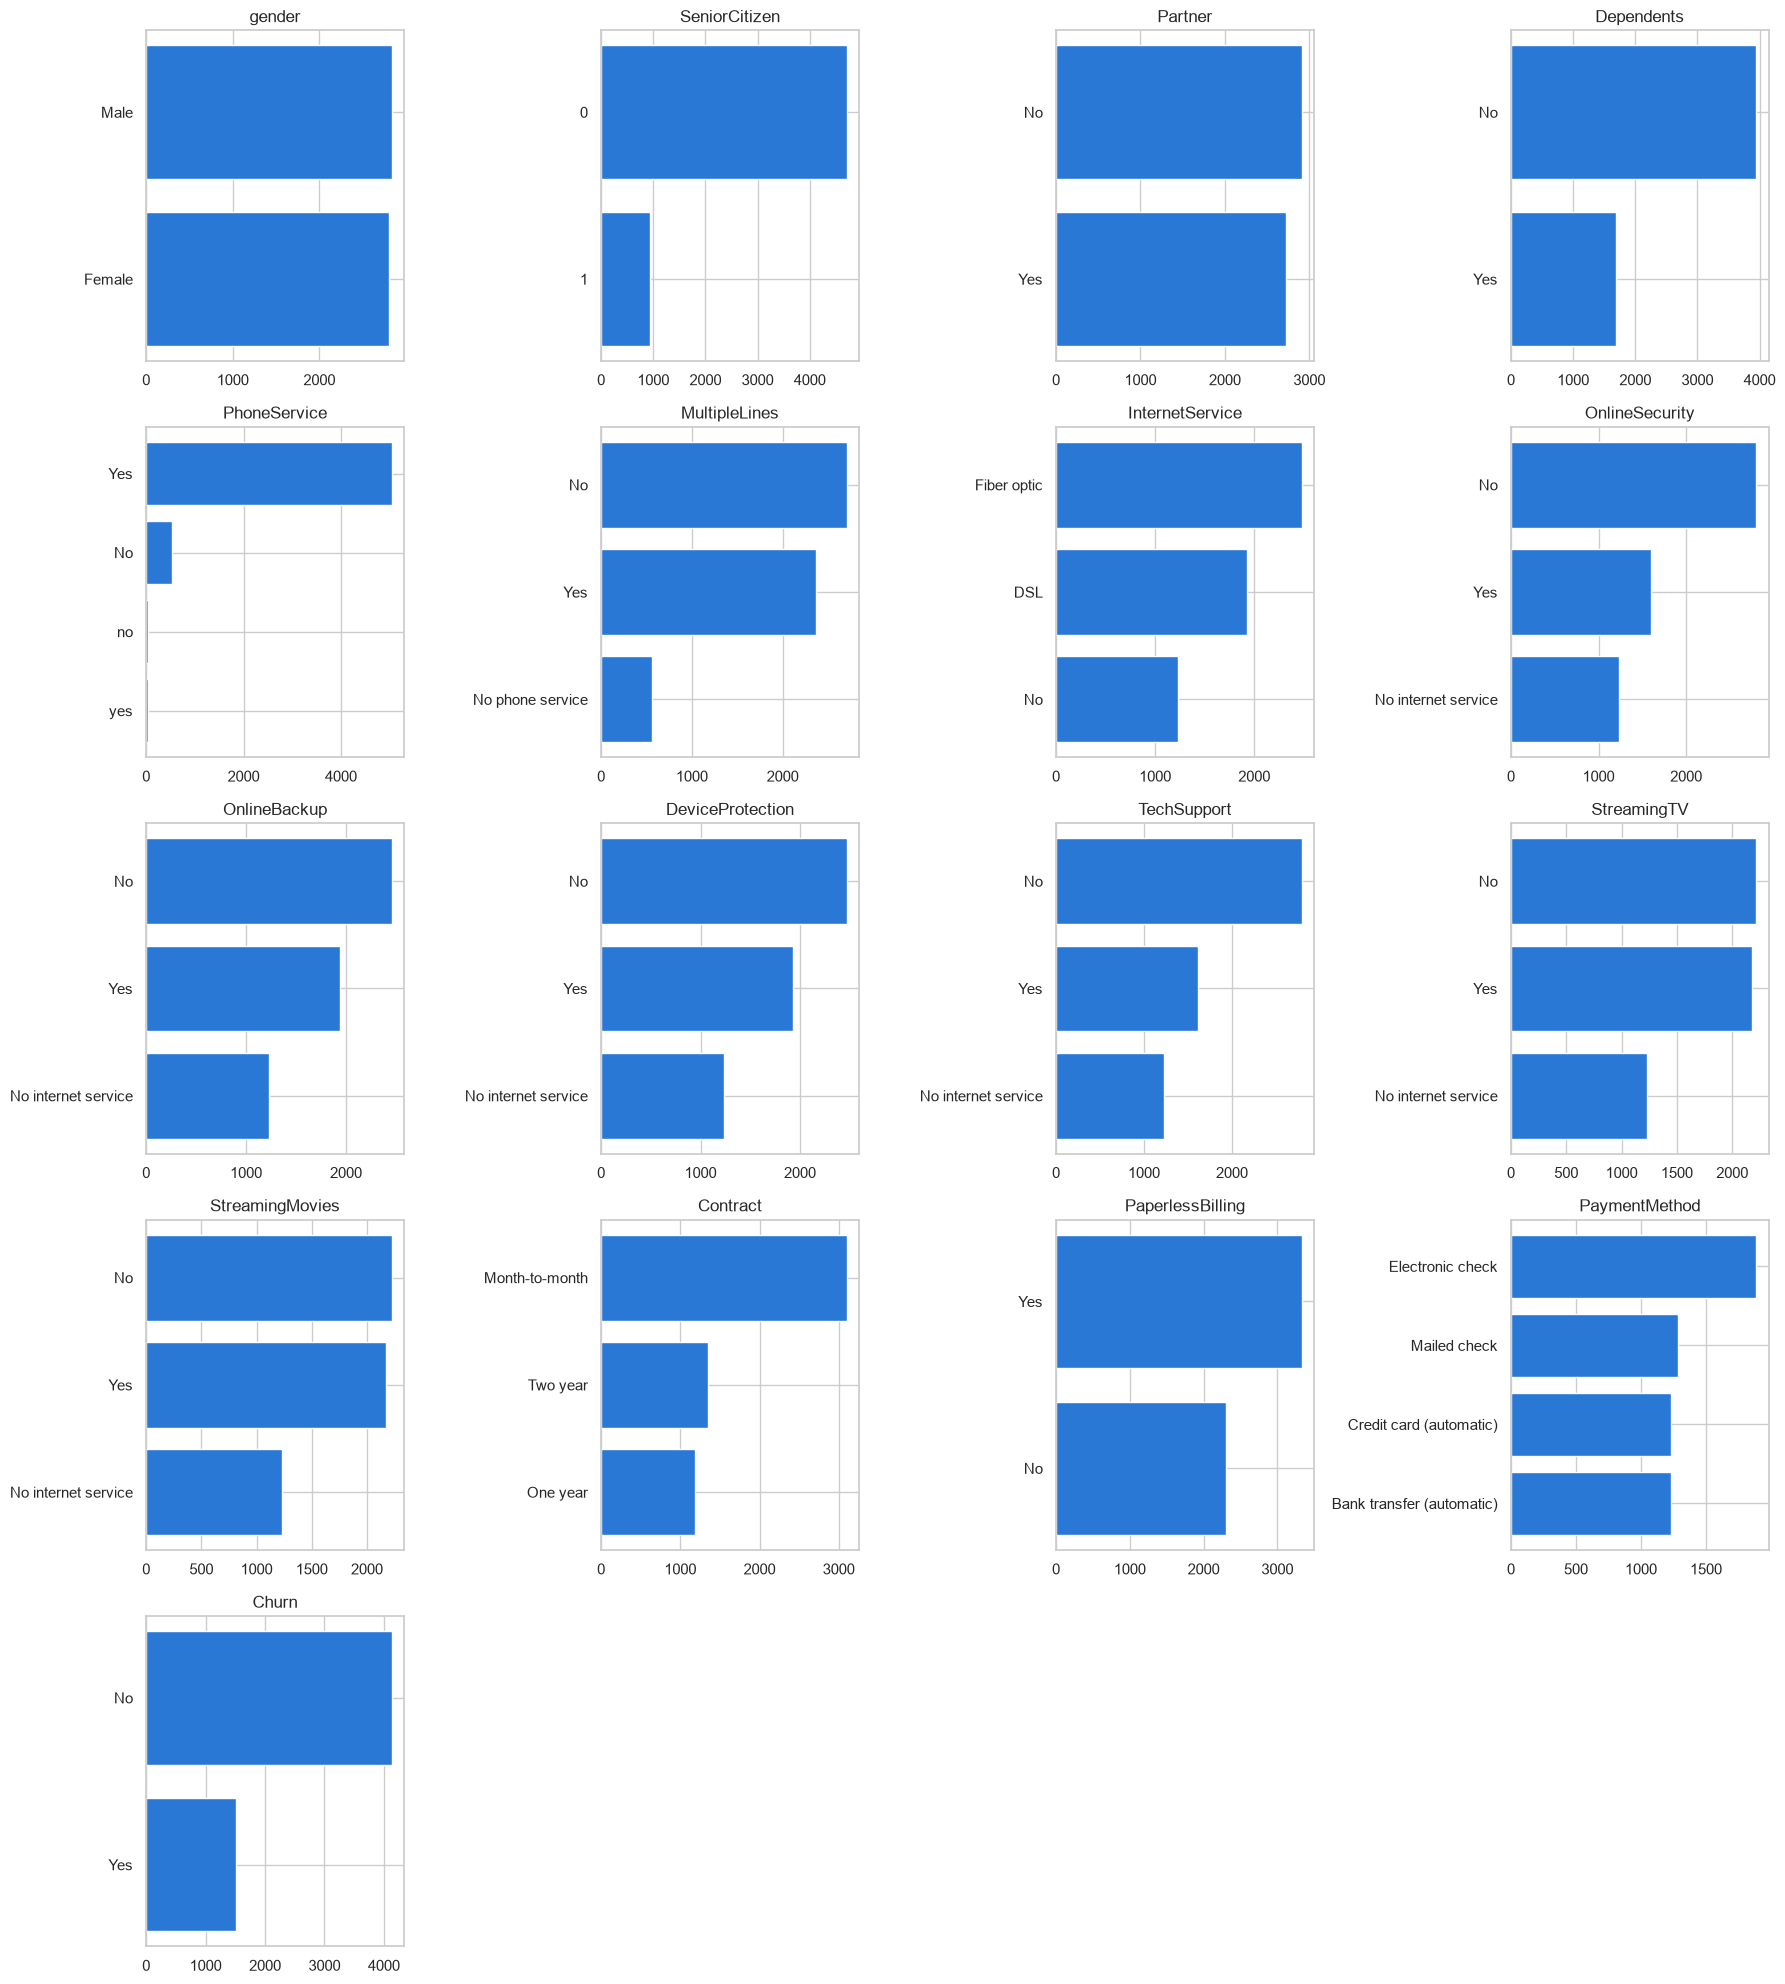

In [34]:
fig, eixos = plt.subplots(5, 4, figsize=(18, 20))
eixos = eixos.flatten()

for posicao, coluna in enumerate(colunas_categoricas):
    frequencias = dados[coluna].astype(str).value_counts()
    eixos[posicao].barh(frequencias.index, frequencias.values, color=COR_PRINCIPAL)
    eixos[posicao].set_title(coluna)
    eixos[posicao].invert_yaxis()

# Remove os quadros que sobraram vazios
for posicao in range(len(colunas_categoricas), len(eixos)):
    eixos[posicao].set_visible(False)

plt.tight_layout()
plt.show()

**Interpretação (fatos observados):**

- **Churn:** 4.130 `No` (73,3%) e 1.504 `Yes` (26,7%) → a variável de interesse é **desbalanceada**: cerca de 1 em cada 4 clientes cancelou.
- **Contract:** predomina `Month-to-month` (55,0%).
- **InternetService:** `Fiber optic` (44,0%), `DSL` (34,1%) e sem internet (21,9%).
- **PaymentMethod:** `Electronic check` é o mais comum (33,5%).
- **SeniorCitizen:** 16,5% dos clientes estão marcados como 1.
- **gender:** praticamente equilibrado (50,3% / 49,7%).
- **Categorias raras:** apenas os valores `no` e `yes` em minúsculas de `PhoneService`, confirmando que são erros de grafia, não categorias reais.

### Variável de texto `CustomerFeedback`

In [35]:
tamanho_feedback = dados[COLUNA_TEXTO].str.len()
print("Quantidade de caracteres por feedback:")
print(tamanho_feedback.describe().round(1))
print(f"\nFeedbacks distintos: {dados[COLUNA_TEXTO].nunique()} de {len(dados)}")
print("\nExemplo completo:")
print(dados.loc[0, COLUNA_TEXTO])

Quantidade de caracteres por feedback:
count    5634.0
mean      460.2
std        67.9
min       277.0
25%       414.0
50%       454.0
75%       499.0
max       844.0
Name: CustomerFeedback, dtype: float64

Feedbacks distintos: 5634 de 5634

Exemplo completo:
I have been a customer with this internet provider for over four years now and I have been satisfied with the service. The DSL internet is reliable and I have had no issues with connectivity. The monthly charges of $68.75 are reasonable for the service I receive. I appreciate the convenience of paying with electronic check. Overall, I am happy with my experience and have no plans to switch providers.


**Fato:** todo cliente tem um feedback, todos são diferentes e têm entre 277 e 844 caracteres. O texto está em inglês e cita informações das outras colunas (tempo de cliente, tipo de internet, valor mensal, forma de pagamento).

**Implicação:** é uma variável de **texto livre**; análises de texto aprofundadas estão fora do escopo desta etapa. A relação com o `Churn` é examinada em 7.4.

## 7.3 Variáveis temporais

**Fato:** não há colunas de data (seção 4). A única variável relacionada a tempo é `tenure`, uma **duração**. Abaixo verificamos qual é a unidade dessa duração, usando o próprio texto do feedback como evidência.

In [36]:
# Quantos feedbacks citam literalmente "<tenure> months"?
cita_tenure_em_meses = [
    f"{int(tempo)} months" in texto
    for texto, tempo in zip(dados[COLUNA_TEXTO], tenure_numerico.fillna(-1))
]
quantidade_cita_meses = sum(cita_tenure_em_meses)
print(f"Feedbacks que citam '<tenure> months': {quantidade_cita_meses} ({quantidade_cita_meses / len(dados) * 100:.1f}%)")

# Exemplo de cliente com tenure 22
exemplo = dados[dados["tenure"] == "22"].iloc[0]
print(f"\ntenure = {exemplo['tenure']}")
print(exemplo[COLUNA_TEXTO][:120], "...")

Feedbacks que citam '<tenure> months': 2995 (53.2%)

tenure = 22
I have been a customer with this company for 22 months now and I have been satisfied with the service. I have not experi ...


**Resultado:**

- **Fato:** 53,2% dos feedbacks citam literalmente o valor de `tenure` seguido de "months" (os demais usam expressões como "over four years").
- **Inferência (confiança média-alta):** `tenure` está em **meses**. Isso é coerente com a seção 6.5 (TotalCharges ≈ tenure × MonthlyCharges) e com o máximo de 72 (= 6 anos).
- **Limitação:** sem coluna de data, **não é possível determinar** a data de referência da base, o período coberto nem a data em que cada cliente entrou ou saiu. Também não é possível construir séries temporais.

## 7.4 Relações entre variáveis (exploração inicial)

Ainda não é a EDA completa. O objetivo é identificar **relações promissoras** para aprofundar depois.`Churn` como a variável de cancelamento e pede para "investigar as características da carteira e suas relações com o histórico de cancelamento", o `Churn` é o eixo destas comparações.

> Todas as relações abaixo são **associações**, não causas.

In [37]:
taxa_churn_geral = (dados[COLUNA_ALVO] == "Yes").mean() * 100
print(f"Taxa de churn geral: {taxa_churn_geral:.1f}%")


def calcular_taxa_churn(df, coluna):
    # Quantidade de clientes e % de cancelamento em cada categoria da coluna
    agrupado = df.groupby(coluna)[COLUNA_ALVO]
    resultado = pd.DataFrame({
        "clientes": agrupado.size(),
        "taxa_churn_pct": (agrupado.apply(lambda serie: (serie == "Yes").mean()) * 100).round(1),
    })
    return resultado.sort_values("taxa_churn_pct", ascending=False)

Taxa de churn geral: 26.7%


**Por que estas variáveis:** representam os três grupos: relacionamento/contrato (`Contract`, `PaymentMethod`, `PaperlessBilling`), serviços (`InternetService`, `OnlineSecurity`, `TechSupport`) e perfil do cliente (`SeniorCitizen`, `Partner`, `Dependents`, `gender`).

In [38]:
colunas_para_comparar = [
    "Contract", "PaymentMethod", "PaperlessBilling",
    "InternetService", "OnlineSecurity", "TechSupport",
    "SeniorCitizen", "Partner", "Dependents", "gender",
]

for coluna in colunas_para_comparar:
    print(f"\n=== Churn por {coluna} ===")
    print(calcular_taxa_churn(dados, coluna))


=== Churn por Contract ===
                clientes  taxa_churn_pct
Contract                                
Month-to-month      3099            42.7
One year            1188            11.6
Two year            1347             3.3

=== Churn por PaymentMethod ===
                           clientes  taxa_churn_pct
PaymentMethod                                      
Electronic check               1888            45.1
Mailed check                   1283            19.4
Bank transfer (automatic)      1229            17.2
Credit card (automatic)        1234            15.6

=== Churn por PaperlessBilling ===
                  clientes  taxa_churn_pct
PaperlessBilling                          
Yes                   3327            33.7
No                    2307            16.6

=== Churn por InternetService ===
                 clientes  taxa_churn_pct
InternetService                          
Fiber optic          2477            42.1
DSL                  1924            19.4
No         

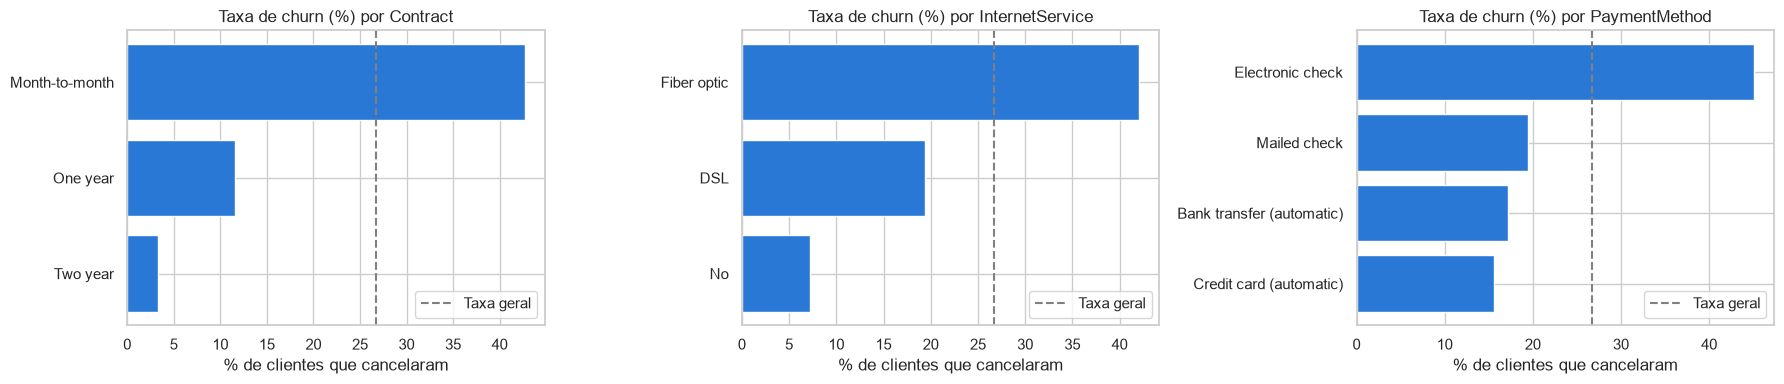

In [39]:
fig, eixos = plt.subplots(1, 3, figsize=(18, 4))

for eixo, coluna in zip(eixos, ["Contract", "InternetService", "PaymentMethod"]):
    taxas = calcular_taxa_churn(dados, coluna)["taxa_churn_pct"].sort_values()
    eixo.barh(taxas.index, taxas.values, color=COR_PRINCIPAL)
    eixo.axvline(taxa_churn_geral, color="gray", linestyle="--", label="Taxa geral")
    eixo.set_title(f"Taxa de churn (%) por {coluna}")
    eixo.set_xlabel("% de clientes que cancelaram")
    eixo.legend()

plt.tight_layout()
plt.show()

**Interpretação (fatos, com as taxas calculadas acima):**

- `Contract`: Month-to-month **42,7%**, One year 11,6%, Two year 3,3%.
- `InternetService`: Fiber optic **42,1%**, DSL 19,4%, sem internet 7,2%.
- `PaymentMethod`: Electronic check **45,1%**; os demais entre 15,6% e 19,4%.
- `SeniorCitizen = 1`: 42,3% contra 23,6%.
- `gender`: diferença pequena (27,2% vs 26,2%).

### Medidas numéricas por situação de churn

**Pergunta:** clientes que cancelaram têm tempo de relacionamento e valores diferentes dos que permaneceram?

In [40]:
dados_numericos.groupby(dados[COLUNA_ALVO]).median().round(2)

,tenure,MonthlyCharges,TotalCharges,MonthlyIncome
Churn,,,,
No,37.0,64.35,1672.25,5048.0
Yes,10.0,79.82,753.15,5214.5


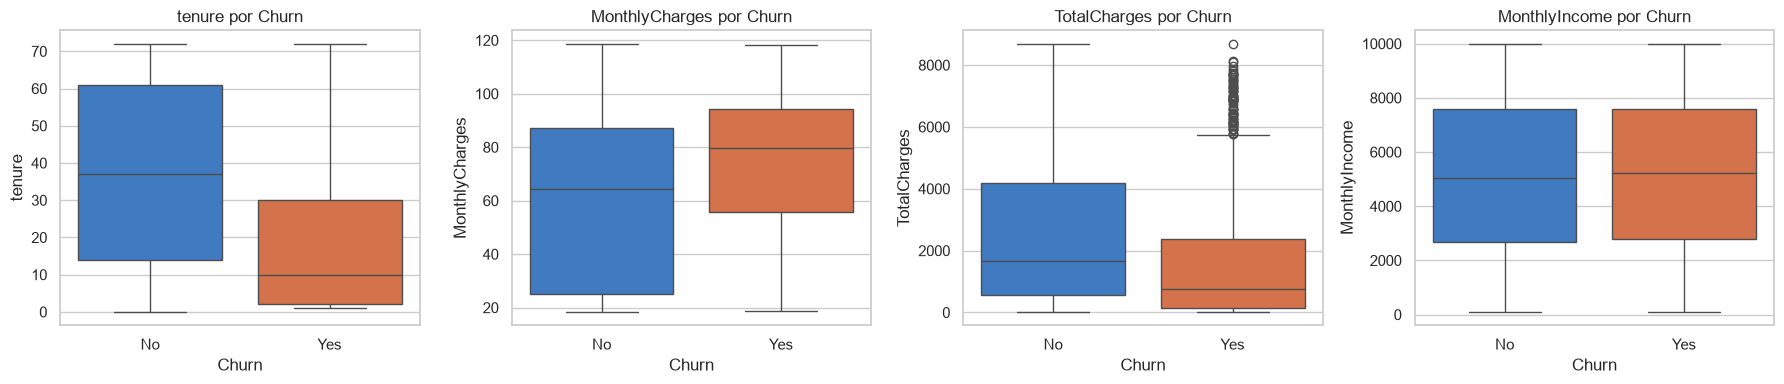

In [41]:
fig, eixos = plt.subplots(1, 4, figsize=(18, 4))

for eixo, coluna in zip(eixos, dados_numericos.columns):
    sns.boxplot(
        x=dados[COLUNA_ALVO], y=dados_numericos[coluna], hue=dados[COLUNA_ALVO],
        palette=CORES_CHURN, legend=False, ax=eixo,
    )
    eixo.set_title(f"{coluna} por Churn")
    eixo.set_xlabel("Churn")

plt.tight_layout()
plt.show()

**Interpretação:**

- **Fato:** quem cancelou tem mediana de `tenure` de **10 meses** contra **37** de quem ficou, e mediana de `MonthlyCharges` maior (79,82 vs 64,35).
- **Fato:** `MonthlyIncome` praticamente não muda entre os grupos (5.214,5 vs 5.048,0).
- **Fato:** no boxplot de `TotalCharges`, o grupo `Yes` mostra pontos além dos bigodes. São valores altos **dentro desse grupo** (clientes que acumularam muito e mesmo assim cancelaram), não erros: na base inteira o IQR não aponta outliers (seção 6.6).
- **Inferência:** o cancelamento parece concentrado nos primeiros meses de relacionamento, a ser aprofundado com faixas de `tenure`.

### Correlação entre as medidas numéricas

Usamos Spearman porque `TotalCharges` é assimétrica e Spearman é menos sensível a isso que Pearson.

In [42]:
dados_numericos.corr(method="spearman").round(3)

,tenure,MonthlyCharges,TotalCharges,MonthlyIncome
tenure,1.000,0.278,0.887,-0.000
MonthlyCharges,0.278,1.000,0.638,0.012
TotalCharges,0.887,0.638,1.000,0.008
MonthlyIncome,-0.000,0.012,0.008,1.000


**Interpretação:**

- **Fato:** `tenure` × `TotalCharges` = 0,89 e `MonthlyCharges` × `TotalCharges` = 0,64 → esperado, porque `TotalCharges` é (aproximadamente) a combinação das duas.
- **Fato:** `MonthlyIncome` tem correlação praticamente **zero** com todas as outras medidas.
- **Implicação:** `TotalCharges` é em grande parte **redundante** com `tenure` × `MonthlyCharges`. Somando à distribuição uniforme (7.1), reforça-se a **hipótese** de que `MonthlyIncome` não traz informação relacionada às demais variáveis.

### `CustomerFeedback` × `Churn`

**Por que analisar:** se o texto descreve a decisão de cancelar, ele pode ter sido escrito **depois** do cancelamento. Isso importa para saber como usá-lo (descrição do motivo, não "previsão").

In [43]:
TERMOS_CANCELAMENTO = "churn|switch|cancel|leav"
menciona_cancelamento = dados[COLUNA_TEXTO].str.contains(TERMOS_CANCELAMENTO, case=False)

print("% de feedbacks que mencionam termos de cancelamento, por Churn:")
print((menciona_cancelamento.groupby(dados[COLUNA_ALVO]).mean() * 100).round(1))

cita_valor_mensal = [
    f"${valor}" in texto
    for texto, valor in zip(dados[COLUNA_TEXTO], dados["MonthlyCharges"])
]
print(f"\nFeedbacks que citam o valor exato de MonthlyCharges: {sum(cita_valor_mensal) / len(dados) * 100:.1f}%")

% de feedbacks que mencionam termos de cancelamento, por Churn:
Churn
No      56.6
Yes    100.0
Name: CustomerFeedback, dtype: float64

Feedbacks que citam o valor exato de MonthlyCharges: 88.7%


**Resultado:**

- **Fato:** 100% dos feedbacks de clientes com `Churn = Yes` usam termos de cancelamento/troca (ex.: "decided to churn"); entre `Churn = No` são 56,6% (geralmente em frases negativas, como "no plans to switch").
- **Fato:** 88,7% dos feedbacks citam o valor exato de `MonthlyCharges` com símbolo `$`.
- **Inferência:** o feedback foi produzido **conhecendo o desfecho** do cliente e os dados da própria linha. Portanto, ele descreve o cancelamento, mas não serve para antecipá-lo.
- **Hipótese:** o texto pode ter sido gerado automaticamente a partir das colunas estruturadas. Não é possível confirmar com as fontes disponíveis.
- **Inferência:** o uso de `$` sugere que os valores monetários estão em **dólar** (confiança média).

---
# 8. Granularidade e identificadores

**Objetivo:** responder com evidências "o que representa uma linha?". Não assumimos que `customerID` é chave primária só pelo nome.

In [44]:
linhas_por_cliente = dados.groupby(COLUNA_ID).size()

print(f"Linhas na base: {len(dados)}")
print(f"customerID distintos: {dados[COLUNA_ID].nunique()}")
print(f"customerID nulos: {dados[COLUNA_ID].isna().sum()}")
print("\nQuantas linhas cada cliente possui:")
print(linhas_por_cliente.value_counts())

Linhas na base: 5634
customerID distintos: 5634
customerID nulos: 0

Quantas linhas cada cliente possui:
1    5634
Name: count, dtype: int64


**Evidências:**

1. **Fato:** `customerID` é único (5.634 valores distintos em 5.634 linhas), sem nulos e com formato padronizado (seção 6.4).
2. **Fato:** cada cliente aparece em exatamente **uma** linha → não é necessária chave composta.
3. **Fato:** não há coluna de data, mês ou período → não há várias "fotografias" do mesmo cliente misturadas.
4. **Fato:** todas as colunas descrevem o mesmo nível (o cliente): perfil, serviços, contrato, valores e cancelamento. Não há colunas de nível de transação (ex.: uma fatura ou uma chamada).
5. **Fato (PDF):** "Cada registro corresponde a um cliente da carteira histórica da Terra Signal."

### Resposta: "Uma linha do dataset representa o quê?"

> **Uma linha representa um cliente da carteira histórica da Terra Signal, em um único retrato (snapshot), com suas características, serviços contratados, condições de contrato, valores cobrados, feedback e situação de cancelamento.** A chave primária candidata é `customerID`.

**O que não é possível determinar:** a data em que esse retrato foi tirado e se as informações de serviços/valores se referem ao momento do cancelamento ou a outro momento.

---
# 9. Dicionário de dados

Construído **a partir da exploração**:

- **Campos quantitativos** (tipo, nulos, % nulos, valores únicos, exemplo): calculados pela função `resumir_colunas` (seção 5).
- **Campos interpretativos** (descrição, significado, confiança, observações): escritos pelo grupo, com base nas evidências deste notebook e no PDF.

**Escala de confiança:** **Alta** = evidência clara (PDF ou dados); **Média** = interpretação provável; **Baixa** = hipótese a validar.

In [45]:
# (descrição, possível significado no negócio, confiança, observações)
descricoes = {
    "customerID": (
        "Identificador do cliente", "Chave que identifica cada cliente da carteira", "Alta",
        "Único por linha; formato 0000-AAAAA (seções 6.4 e 8)"),
    "gender": (
        "Gênero do cliente (Male/Female)", "Perfil demográfico", "Alta",
        "Dado pessoal; distribuição equilibrada"),
    "SeniorCitizen": (
        "Indicador 0/1 de cliente idoso", "Perfil demográfico (faixa etária)", "Média",
        "Critério de idade não informado; usa 0/1 enquanto as demais booleanas usam Yes/No"),
    "Partner": (
        "Indica se o cliente possui parceiro(a)", "Perfil familiar", "Média",
        "Significado inferido pelo nome; PDF classifica como dado do cliente"),
    "Dependents": (
        "Indica se o cliente possui dependentes", "Perfil familiar", "Média",
        "Significado inferido pelo nome; PDF classifica como dado do cliente"),
    "tenure": (
        "Tempo de relacionamento com a empresa", "Tempo como cliente (provavelmente em meses)", "Média",
        "19 valores 'unknown'; lido como texto; unidade inferida (seções 6.5 e 7.3)"),
    "PhoneService": (
        "Possui serviço de telefone (Yes/No)", "Serviço contratado", "Alta",
        "70 valores em minúsculas (yes/no) - seção 6.4"),
    "MultipleLines": (
        "Possui múltiplas linhas telefônicas", "Serviço contratado", "Alta",
        "'No phone service' quando não há telefone; consistente com PhoneService"),
    "InternetService": (
        "Tipo de internet contratada (DSL, Fiber optic, No)", "Serviço contratado", "Alta",
        "Determina os serviços adicionais de internet"),
    "OnlineSecurity": (
        "Possui serviço de segurança online", "Serviço adicional de internet", "Média",
        "'No internet service' quando não há internet"),
    "OnlineBackup": (
        "Possui serviço de backup online", "Serviço adicional de internet", "Média",
        "'No internet service' quando não há internet"),
    "DeviceProtection": (
        "Possui proteção de dispositivo", "Serviço adicional de internet", "Média",
        "'No internet service' quando não há internet"),
    "TechSupport": (
        "Possui suporte técnico", "Serviço adicional de internet", "Média",
        "'No internet service' quando não há internet"),
    "StreamingTV": (
        "Possui streaming de TV", "Serviço adicional de internet", "Média",
        "'No internet service' quando não há internet"),
    "StreamingMovies": (
        "Possui streaming de filmes", "Serviço adicional de internet", "Média",
        "'No internet service' quando não há internet"),
    "Contract": (
        "Tipo de contrato (Month-to-month, One year, Two year)", "Fidelização do cliente", "Alta",
        "Categoria ordinal pela duração"),
    "PaperlessBilling": (
        "Recebe fatura sem papel (digital)", "Forma de cobrança", "Média",
        "PDF classifica em 'Contrato e pagamento'"),
    "PaymentMethod": (
        "Forma de pagamento", "Forma de cobrança", "Alta",
        "4 categorias; 2 automáticas e 2 não automáticas"),
    "MonthlyCharges": (
        "Valor cobrado por mês", "Receita mensal por cliente (provavelmente em dólar)", "Média",
        "Moeda inferida pelo símbolo $ no feedback (seção 7.4)"),
    "TotalCharges": (
        "Valor total cobrado durante o relacionamento", "Receita acumulada do cliente", "Média",
        "278 nulos; ~ tenure x MonthlyCharges (seção 6.5)"),
    "Churn": (
        "Situação de cancelamento (Yes/No)", "Indica se o cliente cancelou", "Alta",
        "Definida no PDF; desbalanceada (26,7% Yes)"),
    "CustomerFeedback": (
        "Comentário em texto do cliente", "Percepção do cliente sobre o serviço", "Média",
        "Escrito conhecendo o desfecho; momento da coleta não determinado (seção 7.4)"),
    "MonthlyIncome": (
        "Renda mensal (pelo nome)", "Significado não determinado a partir das fontes disponíveis", "Baixa",
        "Unidade/moeda e titular não informados; distribuição uniforme e sem correlação (seções 7.1 e 7.4)"),
}

colunas_interpretativas = ["descricao", "significado_negocio", "confianca", "observacoes"]
tabela_descricoes = pd.DataFrame.from_dict(descricoes, orient="index", columns=colunas_interpretativas)

dicionario_dados = resumo_colunas[
    ["tipo_python", "tipo_conceitual", "nulos", "pct_nulos", "valores_unicos", "exemplo"]
].join(tabela_descricoes)

dicionario_dados.index.name = "coluna"
dicionario_dados

,tipo_python,tipo_conceitual,nulos,pct_nulos,valores_unicos,exemplo,descricao,significado_negocio,confianca,observacoes
coluna,,,,,,,,,,
customerID,str,identificador,0,0.00,5634,4578-PHJYZ,Identificador do cliente,Chave que identifica cada cliente da carteira,Alta,Único por linha; formato 0000-AAAAA (seções 6.4 e 8)
gender,str,categórica nominal (2 níveis),0,0.00,2,Male,Gênero do cliente (Male/Female),Perfil demográfico,Alta,Dado pessoal; distribuição equilibrada
SeniorCitizen,int64,booleana codificada 0/1,0,0.00,2,0,Indicador 0/1 de cliente idoso,Perfil demográfico (faixa etária),Média,Critério de idade não informado; usa 0/1 enquanto as dem...
Partner,str,booleana (Yes/No),0,0.00,2,Yes,Indica se o cliente possui parceiro(a),Perfil familiar,Média,Significado inferido pelo nome; PDF classifica como dado...
Dependents,str,booleana (Yes/No),0,0.00,2,Yes,Indica se o cliente possui dependentes,Perfil familiar,Média,Significado inferido pelo nome; PDF classifica como dado...
tenure,str,numérica discreta (duração),0,0.00,74,52,Tempo de relacionamento com a empresa,Tempo como cliente (provavelmente em meses),Média,19 valores 'unknown'; lido como texto; unidade inferida ...
PhoneService,str,booleana (Yes/No),0,0.00,4,Yes,Possui serviço de telefone (Yes/No),Serviço contratado,Alta,70 valores em minúsculas (yes/no) - seção 6.4
MultipleLines,str,categórica nominal (3 níveis),0,0.00,3,No,Possui múltiplas linhas telefônicas,Serviço contratado,Alta,'No phone service' quando não há telefone; consistente c...
InternetService,str,categórica nominal (3 níveis),0,0.00,3,DSL,"Tipo de internet contratada (DSL, Fiber optic, No)",Serviço contratado,Alta,Determina os serviços adicionais de internet


In [46]:
# Conferência: toda coluna da base tem descrição, e nenhuma descrição sobra
colunas_sem_descricao = set(dados.columns) - set(descricoes)
descricoes_sem_coluna = set(descricoes) - set(dados.columns)
print("Colunas sem descrição:", colunas_sem_descricao or "nenhuma")
print("Descrições sem coluna:", descricoes_sem_coluna or "nenhuma")
print("\nDistribuição da confiança:")
print(dicionario_dados["confianca"].value_counts())

Colunas sem descrição: nenhuma
Descrições sem coluna: nenhuma

Distribuição da confiança:
confianca
Média    14
Alta      8
Baixa     1
Name: count, dtype: int64


---
# 10. Entendimento do negócio

### A. Evidências (fatos observados no CSV e/ou PDF)

- A Terra Signal é uma empresa **fictícia** de telecomunicações (PDF).
- Cada linha é um cliente; há 5.634 clientes (CSV e PDF).
- A empresa oferece telefone (linha única ou múltiplas) e internet (DSL ou fibra), além de 6 serviços adicionais de internet (CSV).
- Há três tipos de contrato e quatro formas de pagamento (CSV).
- 26,7% dos clientes têm `Churn = Yes` (CSV); o PDF define `Churn` como a situação de cancelamento.
- O problema proposto pelo professor é **estruturar, processar, armazenar e disponibilizar com segurança** os dados para apoiar a **compreensão da carteira de clientes** (PDF).

### B. Inferências (deduções razoáveis)

- A base representa o processo de **gestão da carteira de assinantes** (contratação de serviços, cobrança recorrente e cancelamento).
- `tenure` está em meses e `TotalCharges` é o valor acumulado cobrado (seções 6.5 e 7.3).
- Os valores monetários provavelmente estão em dólar (símbolo `$` no feedback).
- O cancelamento está associado a contratos mensais, internet por fibra, pagamento por cheque eletrônico e pouco tempo de relacionamento (seção 7.4), **associação, não causa**.

### C. Hipóteses (precisam ser confirmadas)

- `MonthlyIncome` seria a renda mensal do cliente; sua distribuição uniforme e ausência de correlação sugerem que pode ter sido **gerada artificialmente**.
- `CustomerFeedback` pode ter sido gerado automaticamente a partir das demais colunas.
- A estrutura das colunas é muito semelhante a bases públicas de churn de telecomunicações. *(Conhecimento externo, não verificável com as fontes do projeto; não deve ser usado como fonte.)*
- Não se sabe se os clientes com `Churn = Yes` já saíram ou se estão em processo de saída

---
# 11. Perguntas de negócio

Todas podem ser respondidas com as colunas existentes e serão aprofundadas na EDA

| # | Pergunta | Variáveis envolvidas | Análise necessária | Possível indicador |
|---|---|---|---|---|
| 1 | Qual é a taxa de cancelamento da carteira? | `Churn` | Proporção | Taxa de churn (%) |
| 2 | Como a taxa de churn varia por tipo de contrato? | `Contract`, `Churn` | Taxa por categoria | Taxa de churn por contrato |
| 3 | Clientes com menos tempo de relacionamento cancelam mais? | `tenure`, `Churn` | Faixas de `tenure` (ex.: 0–12, 13–24, ...) e taxa por faixa; comparação de medianas | Taxa de churn por faixa de tempo |
| 4 | Clientes que cancelaram pagam mensalidades diferentes dos que ficaram? | `MonthlyCharges`, `Churn` | Comparação de médias/medianas; taxa por faixa de valor | Mensalidade mediana por grupo |
| 5 | O tipo de internet e os serviços adicionais (ex.: `TechSupport`, `OnlineSecurity`) estão associados ao churn? | `InternetService`, 6 serviços adicionais, `Churn` | Taxa por categoria; tabela cruzada | Taxa de churn por serviço |
| 6 | A quantidade de serviços contratados se relaciona com o cancelamento? | `PhoneService`, `MultipleLines`, `InternetService`, 6 serviços, `Churn` | Variável derivada "nº de serviços"; taxa por quantidade | Taxa de churn por nº de serviços |
| 7 | Forma de pagamento e fatura digital estão associadas ao churn? | `PaymentMethod`, `PaperlessBilling`, `Churn` | Taxa por categoria e combinação | Taxa de churn por forma de pagamento |
| 8 | Qual o perfil demográfico dos clientes que cancelaram? | `SeniorCitizen`, `Partner`, `Dependents`, `gender`, `Churn` | Taxas por grupo; tabelas cruzadas | Taxa de churn por perfil |
| 9 | Quanto da receita mensal está associado a clientes que cancelaram? | `MonthlyCharges`, `Churn` | Soma por grupo | % da receita mensal dos cancelados |
| 10 | `MonthlyIncome` tem relação com o valor contratado ou com o churn? | `MonthlyIncome`, `MonthlyCharges`, `Churn` | Correlação e comparação entre grupos | Correlação; renda mediana por grupo |

A pergunta 10 serve também para **validar a utilidade** de `MonthlyIncome`, cuja confiabilidade foi questionada na seção 7.

In [47]:
# Prévia da pergunta 9, apenas para confirmar que a base permite respondê-la
receita_mensal_total = dados["MonthlyCharges"].sum()
receita_mensal_cancelados = dados.loc[dados[COLUNA_ALVO] == "Yes", "MonthlyCharges"].sum()
print(f"Receita mensal associada a clientes com Churn = Yes: {receita_mensal_cancelados / receita_mensal_total * 100:.1f}% do total")

Receita mensal associada a clientes com Churn = Yes: 30.8% do total


**Observação:** 26,7% dos clientes respondem por 30,8% da receita mensal — um indício de que quem cancela paga, em média, mensalidades maiores (coerente com a seção 7.4).

---
# 12. Principais achados

### Estrutura
- 5.634 linhas × 23 colunas (confere com o PDF).
- **Granularidade:** 1 linha = 1 cliente (snapshot); `customerID` é chave única.
- 4 medidas numéricas (`tenure`, `MonthlyCharges`, `TotalCharges`, `MonthlyIncome`), 1 identificador, 1 texto livre e 17 categóricas/booleanas.
- Nenhuma variável de data.

### Qualidade
- `TotalCharges`: 278 nulos (4,93%), 10 deles em clientes com `tenure = 0`.
- `tenure`: 19 valores `unknown` (0,34%), o que fez a coluna ser lida como texto.
- `PhoneService`: 70 valores em minúsculas (1,24%).
- `SeniorCitizen` codificada como 0/1, diferente das demais booleanas (Yes/No).
- Sem duplicidades, sem espaços extras, sem outliers pelo IQR; regras entre colunas (telefone e internet) 100% consistentes.

### Negócio
- Variável central: `Churn` (26,7% de cancelamento).
- Relações promissoras: `Contract`, `InternetService`, `PaymentMethod`, `tenure`, `MonthlyCharges`, `SeniorCitizen`.
- Indicadores potenciais: taxa de churn por segmento, tempo mediano de relacionamento, ticket médio, % da receita mensal dos cancelados.

### Limitações
- Sem data de referência: não é possível analisar evolução no tempo nem saber quando cada cliente cancelou.
- Unidade de `tenure` e moeda dos valores são **inferidas**, não documentadas.
- `MonthlyIncome`: significado e unidade não determinados; comportamento sugere dado artificial.
- `CustomerFeedback` reflete o desfecho: não pode ser usado como sinal "antecipado" de churn.
- Base fictícia: conclusões valem para a Terra Signal, não para o mercado real.
- Associações observadas não indicam causalidade.

---
# 13. Preparação para a Arquitetura Medalhão (proposta conceitual)

### Bronze — dado bruto, preservado

- Ingestão do `history.csv` **sem nenhuma alteração** de valores: todas as colunas como texto (inclusive `tenure` com `unknown`, `PhoneService` com minúsculas e os nulos de `TotalCharges`).
- **Rastreabilidade:** adicionar apenas colunas técnicas de controle, nome do arquivo de origem e data/hora da ingestão. Com Delta Lake, o histórico de versões da tabela permite consultar o estado anterior a qualquer carga.
- Objetivo: poder sempre voltar à fonte e reproduzir as camadas seguintes.

### Silver — dado limpo e padronizado

| Problema encontrado (seção) | Transformação proposta | Decisão a tomar pelo trio |
|---|---|---|
| `tenure` com `unknown` e tipo texto (6.2) | `unknown` → nulo; converter para inteiro | Manter nulo **ou** estimar por `TotalCharges / MonthlyCharges` (sinalizando a estimativa) |
| `TotalCharges` nulo (6.1, 6.5) | Separar os casos `tenure = 0` dos demais | Para `tenure = 0`: 0 ou nulo? Para os demais: manter nulo, estimar por `tenure × MonthlyCharges` ou sinalizar |
| `PhoneService` minúsculas (6.4) | Padronizar para `Yes` / `No` | — |
| `SeniorCitizen` 0/1 (6.4) | Padronizar com as demais booleanas | Usar `Yes/No` em todas **ou** booleano verdadeiro/falso em todas |
| Tipos (5) | Numéricas como número; booleanas padronizadas | — |
| Nomes de colunas | Padronizar a convenção de nomes (ex.: snake_case) | Manter nomes originais ou renomear? |
| Regras de consistência (6.3, 6.5) | Reaplicar as verificações como **testes de qualidade** do pipeline | — |

Colunas de **sinalização** (ex.: `tenure_estimado = True`) preservam a transparência de qualquer imputação.

### Gold — produtos analíticos ligados às perguntas

| Produto Gold (proposta) | Conteúdo | Perguntas atendidas |
|---|---|---|
| Tabela analítica de clientes | Silver + colunas derivadas: faixa de `tenure`, faixa de `MonthlyCharges`, nº de serviços contratados | Base para todas as perguntas e para a EDA |
| Indicadores gerais de churn | Total de clientes, cancelados, taxa de churn, receita mensal total e dos cancelados | 1, 9 |
| Churn por contrato e pagamento | Clientes e taxa de churn por `Contract`, `PaymentMethod`, `PaperlessBilling` | 2, 7 |
| Churn por serviços | Taxa por `InternetService`, por serviço adicional e por nº de serviços | 5, 6 |
| Churn por tempo e valor | Taxa por faixa de `tenure` e de `MonthlyCharges` | 3, 4 |
| Churn por perfil | Taxa por `SeniorCitizen`, `Partner`, `Dependents`, `gender` | 8 |

**Segurança (Gold):** produtos agregados não precisam expor `customerID` nem `CustomerFeedback`.

---
# 16. Checklist da Etapa 1

- [x] Dataset carregado em Python (seção 3)
- [x] Estrutura analisada (seções 3 e 4)
- [x] Tipos identificados — Python e conceitual (seção 5)
- [x] Nulos analisados (seção 6.1)
- [x] Duplicidades analisadas (seção 6.3)
- [x] Valores únicos analisados (seções 4 e 5)
- [x] Inconsistências investigadas (seções 6.2, 6.4 e 6.5)
- [x] Variáveis numéricas analisadas (seção 7.1)
- [x] Variáveis categóricas analisadas (seção 7.2)
- [x] Variáveis temporais analisadas — não existem; `tenure` é duração (seção 7.3)
- [x] Granularidade investigada (seção 8)
- [x] Identificadores investigados (seções 4 e 8)
- [x] Dicionário criado (seção 9)
- [x] Contexto de negócio investigado (seção 10)
- [x] Perguntas de negócio definidas (seção 11)
- [x] Principais achados documentados (seção 12)
- [x] Limitações documentadas (seção 12)
- [x] Próximas etapas planejadas (seções 13 a 15)
- [x] Revisão do notebook pelo trio
- [ ] Validação das dúvidas com o professor